# Nhận dạng chữ số MNIST bằng MLP — bản PyTorch

Chuyển từ notebook Keras gốc: `Example/examples/1. MLP/MNIST_MLP.ipynb`.
Giữ nguyên dữ liệu, kiến trúc, hàm mất mát, optimizer, learning rate, batch size; chỉ thay framework.

**Đối chiếu Keras → PyTorch trong notebook này**

| Keras (gốc) | PyTorch (bản chuyển) |
|---|---|
| `mnist.load_data()` | `load_mnist()` – tải đúng file `mnist.npz` của Keras |
| `keras.utils.to_categorical(y, 10)` (one-hot) | giữ nhãn số nguyên (`torch.long`) vì `nn.CrossEntropyLoss` nhận chỉ số lớp |
| `Flatten` → `Dense(512,'relu')` → `Dropout(0.2)` ×2 → `Dense(10,'softmax')` | `nn.Flatten` → `nn.Linear`+`nn.ReLU`+`nn.Dropout` ×2 → `nn.Linear(512,10)` (logits) |
| `loss='categorical_crossentropy'` + softmax ở lớp ra | `nn.CrossEntropyLoss()` (đã gồm log-softmax) – **không** đặt softmax trong mô hình |
| `SGD(lr=0.01)`, `batch_size=128`, `epochs=30` | `torch.optim.SGD(lr=0.01)`, `DataLoader(batch_size=128, shuffle=True)`, 30 epoch |
| `model.predict(x)` (xác suất) | `F.softmax(model(x), dim=1)` trong `torch.no_grad()` |
| `Model(inputs, outputs=[fc2.output, output])` | trả về đặc trưng `fc2` bằng `forward(..., return_features=True)` |

# Import libraries

In [1]:
import time
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, TensorDataset

# Thư mục gốc bài nộp = thư mục cha gần nhất có chứa "data/"
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data").is_dir())
DATA = ROOT / "data"
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("ROOT =", ROOT, "| device =", DEVICE, "| torch", torch.__version__)

np.random.seed(2024); torch.manual_seed(2024)
num_classes = 10   # 10 classes: 0, 1,..., 9

ROOT = d:\SGU\deep-learning\Tuan13\BTL03_TranQuocAn_3123411009 | device = cpu | torch 2.14.0+cpu


In [2]:
def summary(model, input_size, keras_params=None):
    """Tương đương model.summary() của Keras: tên lớp, output shape, số tham số."""
    rows, hooks = [], []
    for name, m in model.named_modules():
        if len(list(m.children())) == 0 and name:
            hooks.append(m.register_forward_hook(
                lambda mod, i, o, name=name: rows.append(
                    (name, type(mod).__name__, tuple(o.shape) if torch.is_tensor(o) else "-",
                     sum(p.numel() for p in mod.parameters(recurse=False))))))
    was_training = model.training
    model.eval()
    with torch.no_grad():
        model(torch.zeros(1, *input_size, device=next(model.parameters()).device))
    model.train(was_training)
    for h in hooks:
        h.remove()
    print(f"{'Layer':<22}{'Type':<16}{'Output shape':<26}{'Param #':>12}")
    print("=" * 76)
    for n, t, s, p in rows:
        print(f"{n:<22}{t:<16}{str(s):<26}{p:>12,}")
    total = sum(p.numel() for p in model.parameters())
    print("=" * 76)
    print(f"Total params: {total:,}" + (f"   (Keras gốc: {keras_params:,})" if keras_params else ""))

def keras_init(model):
    """Khởi tạo giống mặc định Keras: kernel glorot_uniform, bias = 0
    (PyTorch mặc định dùng kaiming_uniform nên kết quả có thể lệch nhẹ nếu không làm bước này)."""
    for m in model.modules():
        if isinstance(m, (nn.Linear, nn.Conv2d)):
            nn.init.xavier_uniform_(m.weight)
            nn.init.zeros_(m.bias)
    return model

def run_epoch(model, loader, loss_fn, metric_fn=None, optimizer=None, augment=None):
    """1 epoch train (có optimizer) hoặc đánh giá (optimizer=None). Trả về (loss, metric) trung bình theo mẫu."""
    training = optimizer is not None
    model.train(training)
    tot_loss, tot_metric, n = 0.0, 0.0, 0
    with torch.set_grad_enabled(training):
        for xb, yb in loader:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            if augment is not None and training:
                xb = augment(xb)
            out = model(xb)                      # forward
            loss = loss_fn(out, yb)              # loss
            if training:
                optimizer.zero_grad()            # xoá gradient cũ
                loss.backward()                  # backpropagation
                optimizer.step()                 # cập nhật trọng số
            tot_loss += loss.item() * len(xb)
            if metric_fn is not None:
                tot_metric += metric_fn(out.detach(), yb) * len(xb)
            n += len(xb)
    return tot_loss / n, (tot_metric / n if metric_fn is not None else None)


def fit(model, train_loader, val_loader, epochs, optimizer, loss_fn, metric_fn=None, metric_name="accuracy",
        augment=None):
    """Tương đương model.fit(..., validation_data=...): in log mỗi epoch, trả về history."""
    history = {"loss": [], "val_loss": [], metric_name: [], "val_" + metric_name: []}
    for ep in range(1, epochs + 1):
        t0 = time.time()
        tr_loss, tr_m = run_epoch(model, train_loader, loss_fn, metric_fn, optimizer, augment)
        va_loss, va_m = run_epoch(model, val_loader, loss_fn, metric_fn)
        history["loss"].append(tr_loss); history["val_loss"].append(va_loss)
        history[metric_name].append(tr_m); history["val_" + metric_name].append(va_m)
        msg = f"Epoch {ep}/{epochs} - {time.time() - t0:.0f}s - loss: {tr_loss:.4f}"
        if metric_fn is not None:
            msg += f" - {metric_name}: {tr_m:.4f}"
        msg += f" - val_loss: {va_loss:.4f}"
        if metric_fn is not None:
            msg += f" - val_{metric_name}: {va_m:.4f}"
        print(msg, flush=True)
    return history


def accuracy(out, y):
    """Độ chính xác phân loại: so argmax của logits với nhãn số nguyên."""
    return (out.argmax(1) == y).float().mean().item()


def plot_history(history, metric_name="accuracy"):
    keys = [("loss", "val_loss")] + ([(metric_name, "val_" + metric_name)] if history[metric_name][0] is not None else [])
    fig, axes = plt.subplots(1, len(keys), figsize=(6 * len(keys), 3.8))
    axes = np.atleast_1d(axes)
    for ax, (a, b) in zip(axes, keys):
        ax.plot(range(1, len(history[a]) + 1), history[a], marker="o", label="train")
        ax.plot(range(1, len(history[b]) + 1), history[b], marker="o", label="validation")
        ax.set_xlabel("epoch"); ax.set_ylabel(a); ax.grid(alpha=.3); ax.legend()
    plt.tight_layout(); plt.show()

def load_mnist():
    """Tương đương keras.datasets.mnist.load_data(): tải đúng file mnist.npz mà Keras dùng."""
    path = DATA / "mnist.npz"
    if not path.exists():
        import urllib.request
        path.parent.mkdir(parents=True, exist_ok=True)
        urllib.request.urlretrieve("https://storage.googleapis.com/tensorflow/tf-keras-datasets/mnist.npz", path)
    d = np.load(path)
    return (d["x_train"], d["y_train"]), (d["x_test"], d["y_test"])

# (1) Data

In [3]:
(x_train, y_train), (x_test, y_test) = load_mnist()
x_train = x_train.reshape(60000, 28, 28).astype("float32") / 255
x_test = x_test.reshape(10000, 28, 28).astype("float32") / 255
print(x_train.shape[0], "train samples")
print(x_test.shape[0], "test samples")

# Keras: y = keras.utils.to_categorical(y, num_classes)  -> one-hot
# PyTorch: CrossEntropyLoss nhận nhãn số nguyên, one-hot chỉ để minh hoạ:
print("one-hot của nhãn", y_train[0], "=", F.one_hot(torch.tensor(int(y_train[0])), num_classes).tolist())

train_loader = DataLoader(TensorDataset(torch.from_numpy(x_train), torch.from_numpy(y_train).long()), batch_size=128, shuffle=True)
test_loader = DataLoader(TensorDataset(torch.from_numpy(x_test), torch.from_numpy(y_test).long()), batch_size=512)

60000 train samples
10000 test samples
one-hot của nhãn 5 = [0, 0, 0, 0, 0, 1, 0, 0, 0, 0]


# (2) Declare model

In [4]:
class MnistMLP(nn.Module):
    def __init__(self, num_classes=10):
        super().__init__()
        self.flatten = nn.Flatten()                   # matrix ---> vector (28x28 -> 784)
        self.fc1 = nn.Linear(28 * 28, 512)
        self.dropout1 = nn.Dropout(0.2)
        self.fc2 = nn.Linear(512, 512)
        self.dropout2 = nn.Dropout(0.2)
        self.fc3_10ways_softmax = nn.Linear(512, num_classes)   # logits; softmax nằm trong CrossEntropyLoss

    def forward(self, x, return_features=False):
        x = self.flatten(x)
        x = self.dropout1(F.relu(self.fc1(x)))
        feat = F.relu(self.fc2(x))                    # đầu ra lớp fc2 (đặc trưng 512 chiều)
        out = self.fc3_10ways_softmax(self.dropout2(feat))
        return (feat, out) if return_features else out


model = keras_init(MnistMLP(num_classes)).to(DEVICE)
summary(model, (28, 28), keras_params=669_706)

Layer                 Type            Output shape                   Param #
flatten               Flatten         (1, 784)                             0
fc1                   Linear          (1, 512)                       401,920
dropout1              Dropout         (1, 512)                             0
fc2                   Linear          (1, 512)                       262,656
dropout2              Dropout         (1, 512)                             0
fc3_10ways_softmax    Linear          (1, 10)                          5,130
Total params: 669,706   (Keras gốc: 669,706)


# (3) Train defined model

Epoch 1/30 - 4s - loss: 1.2141 - accuracy: 0.6807 - val_loss: 0.5475 - val_accuracy: 0.8676


Epoch 2/30 - 3s - loss: 0.5382 - accuracy: 0.8486 - val_loss: 0.3818 - val_accuracy: 0.8981


Epoch 3/30 - 3s - loss: 0.4278 - accuracy: 0.8766 - val_loss: 0.3281 - val_accuracy: 0.9095


Epoch 4/30 - 3s - loss: 0.3790 - accuracy: 0.8898 - val_loss: 0.2957 - val_accuracy: 0.9167


Epoch 5/30 - 3s - loss: 0.3478 - accuracy: 0.9004 - val_loss: 0.2750 - val_accuracy: 0.9227


Epoch 6/30 - 3s - loss: 0.3214 - accuracy: 0.9073 - val_loss: 0.2599 - val_accuracy: 0.9266


... (21 outputs left out)

Epoch 28/30 - 3s - loss: 0.1389 - accuracy: 0.9600 - val_loss: 0.1194 - val_accuracy: 0.9634


Epoch 29/30 - 3s - loss: 0.1366 - accuracy: 0.9606 - val_loss: 0.1172 - val_accuracy: 0.9639


Epoch 30/30 - 3s - loss: 0.1326 - accuracy: 0.9616 - val_loss: 0.1148 - val_accuracy: 0.9639


> training time is 1.6404 minutes


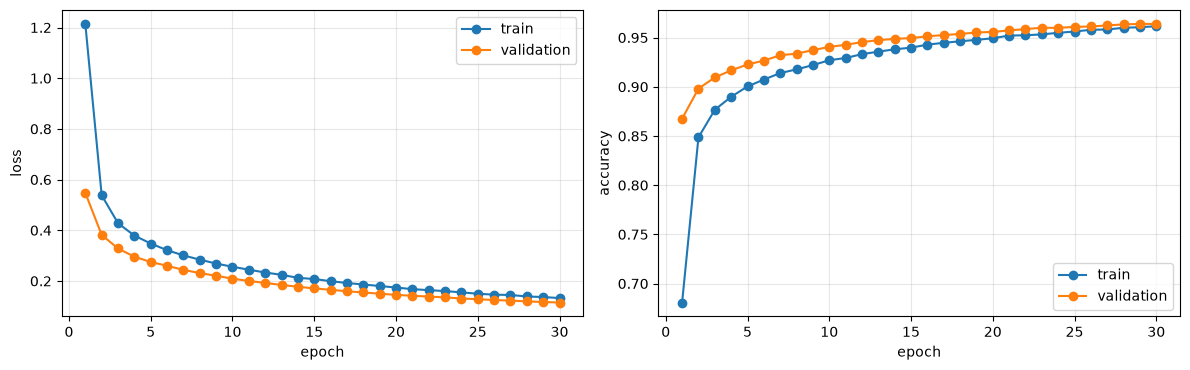

In [5]:
loss_fn = nn.CrossEntropyLoss()                     # 'categorical_crossentropy'
optimizer = torch.optim.SGD(model.parameters(), lr=0.01)
EPOCHS = 30                                         # giống bản Keras gốc

starting_time = time.time()
history = fit(model, train_loader, test_loader, EPOCHS, optimizer, loss_fn, accuracy)
print("> training time is %.4f minutes" % ((time.time() - starting_time) / 60))
plot_history(history)

# (4) Evaluate trained model

In [6]:
test_loss, test_acc = run_epoch(model, test_loader, loss_fn, accuracy)
print("Test loss:", test_loss)
print("Test accuracy:", test_acc)

Test loss: 0.11481101853847504
Test accuracy: 0.9639


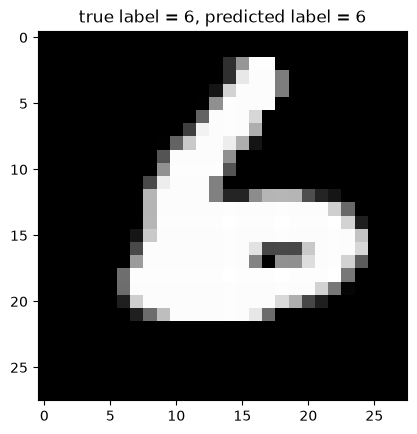

y_pred.shape = (1, 10) | tổng xác suất = [1.]


In [7]:
# select a test image randomly and predict
model.eval()
random_test_index = np.random.choice(x_test.shape[0], size=1)[0]
test_img = x_test[random_test_index]
test_label = y_test[random_test_index]
with torch.no_grad():
    y_pred = F.softmax(model(torch.from_numpy(test_img).unsqueeze(0).to(DEVICE)), dim=1).cpu().numpy()   # (1, 10)
pred_label = np.argmax(y_pred)
plt.imshow(test_img, cmap="gray")
plt.title("true label = %d, predicted label = %d" % (test_label, pred_label))
plt.show()
print("y_pred.shape =", y_pred.shape, "| tổng xác suất =", y_pred.sum(axis=1))

In [8]:
# Tương đương model1 = Model(inputs=model.input, outputs=[fc2.output, model.output])
with torch.no_grad():
    y_feat, logits = model(torch.from_numpy(test_img).unsqueeze(0).to(DEVICE), return_features=True)
print("y_feat.shape =", tuple(y_feat.shape), "| y_pred.shape =", tuple(logits.shape))
print(y_feat[0, :20].cpu().numpy().round(4))

y_feat.shape = (1, 512) | y_pred.shape = (1, 10)
[0.0944 0.     0.1233 0.     0.     0.     1.4046 0.     0.     0.5263
 1.3698 0.8528 0.3421 0.4358 0.     0.     0.     0.     1.7395 1.2431]
